# Robustness of quantized models, v2

## What the v1 run showed (verification)

v1 ran end to end and produced all three noise families with the RobustMQ metrics. Reading the numbers:

**What worked**
- The pipeline is sound: FP32, INT8 and INT4 were all evaluated on identical inputs across adversarially perturbed, naturally corrupted and system-noise conditions, with `AR`, `AAI`, `WCAR`, `mNR`, `NCI`, `SR` and a PGD transfer matrix.
- **One of the paper's two headline predictions reproduced**: natural robustness came out `FP32 > INT8 > INT4` (mNR 41.90 > 41.60 > 40.69), exactly as RobustMQ reports.
- The adversarial collapse at the large budget (`PGD 4/255` -> ~7%) matches the paper's own note that WCAR degrades to almost zero at medium/high budgets.
- Brightness was the least harmful corruption, as in the paper.

**What did not reproduce (and why)**
- The paper's adversarial claim is that *lower bits are more adversarially robust*, i.e. `INT4 > INT8 > FP32`. v1 measured the opposite order (`FP32 > INT8 > INT4`, and only by ~2.5 pp). That is expected: the paper's effect comes from **QAT** models that adapt to rounding, while v1 used **PTQ** models that never adapted. v2 adds QAT to test exactly this.
- INT8 was statistically identical to FP32 (within 0.1-0.7 pp, inside the +/-1.3 pp noise of 1,000 images). So "FP32 > INT8" in v1 was not a real ordering at all.

**Two real bugs v1 exposed**
1. **The transfer-matrix diagonal was 0.0.** The code only wrote `transfer_pgd[attacker][victim]` for `victim != attacker`, so the white-box diagonal was never filled. Fixed in v2 by writing the diagonal too.
2. **The systematic-noise result was an artefact.** `bilinear` resize scored 31.5% while `nearest` scored 57.6%, the reverse of the paper. Downsampling without antialiasing introduces a half-pixel shift plus aliasing, and this model was never trained for translation invariance, so the number measures grid misalignment rather than interpolation quality. v2 uses `antialias=True` for bilinear/bicubic.

**And one configuration problem**: v1 ran on `device: cpu`, so it trained on 12,000 images for 6 epochs and reached a **64.2%** baseline instead of the ~80.7% from the accuracy study. Always use a GPU runtime; v2 prints a loud warning if it sees a CPU.

## What v2 changes

| Requested | How v2 does it |
|---|---|
| `ROBUST_N` to 5,000 | `ROBUST_N = 5000`, lowered automatically on a CPU runtime or with `resnet18`, with a printed explanation |
| A third corruption severity | `SEVERITY_LEVELS = (1, 2, 3)` -> 30 corruption conditions |
| A deeper architecture | `ARCH = "resnet18"` switches to torchvision's **quantizable** ResNet-18 with a CIFAR stem (its skip connections need `FloatFunctional`, which is why the quantizable version is required) |
| A 2-bit row | `INT2-PTQ` and `INT2-QAT`, with 2-bit codes packed four per byte |
| QAT instead of PTQ only | `INT8-QAT` (torch.ao QAT: weights *and* activations) plus optional `INT4-QAT` / `INT2-QAT` weight-only STE fine-tuning |

That makes a **3 bit-widths x 2 training methods + FP32 = 7-model** comparison, which is the design of the original paper.

## Configuration

Everything is in the next cell. Two knobs matter most:

- `ARCH = "cnn"` is the safe default (the same model as the accuracy study). `"resnet18"` is the deeper model; that path is new code and less tested, so if it errors, switch back and tell me.
- `LOW_BIT_QAT = True` adds the 4-bit and 2-bit QAT models, which is where the paper's bit-width effect appears. Set it to `False` for a faster run with only `FP32, INT8-PTQ, INT4-PTQ, INT2-PTQ, INT8-QAT`.

Expect roughly 15-25 minutes on a T4 GPU with `ARCH = "cnn"` and all 7 models: the loop is 7 models x 34 conditions x 5,000 images.


In [1]:
# ===================== CONFIGURATION =====================
ARCH = "cnn"                  # "cnn" (SimpleCNN, safe default) or "resnet18" (deeper, new code path)
ROBUST_N = 5000               # test images for the robustness study (RobustMQ-style protocol)
SEVERITY_LEVELS = (1, 2, 3)   # three corruption severity levels
PGD_STEPS = 10
EPS_LIST = [("1/255", 1 / 255), ("2/255", 2 / 255), ("4/255", 4 / 255)]
LOW_BIT_QAT = True            # also train 4-bit and 2-bit weight-only QAT models
QAT_EPOCHS = 3                # fine-tuning epochs for every QAT model
# =========================================================

import copy
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.nn.utils import parametrize
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 0 if os.name == "nt" else 2

if device.type != "cuda":
    print("!" * 78)
    print("WARNING: no GPU found. Training falls back to 12,000 images x 6 epochs, which gives a")
    print("~64% baseline instead of ~80%, and ROBUST_N is reduced. For numbers that match the")
    print("accuracy study, use Runtime -> Change runtime type -> T4 GPU.")
    print("!" * 78)

if device.type != "cuda" or ARCH == "resnet18":
    ROBUST_N = 1000
    print(f"note: ROBUST_N lowered to {ROBUST_N} because device={device.type} or ARCH={ARCH}. "
          f"Raise it back in the config when you have the time budget.")

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

# perturbations live in pixel space [0, 1] so they can be clipped correctly;
# every model receives NORMALIZE(x)
NORMALIZE = transforms.Normalize(CIFAR_MEAN, CIFAR_STD)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
eval_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])

train_set = datasets.CIFAR10(root="./cifar10", train=True, download=True, transform=train_transform)
calib_set = datasets.CIFAR10(root="./cifar10", train=True, download=True, transform=eval_transform)
pixel_test_set = datasets.CIFAR10(root="./cifar10", train=False, download=True, transform=transforms.ToTensor())

BATCH_SIZE = 128
TRAIN_N = 50000 if device.type == "cuda" else 12000
EPOCHS = 8 if device.type == "cuda" else 6
ROBUST_BATCH = 100
QAT_FINETUNE_LR = 1e-4

train_loader = DataLoader(Subset(train_set, range(TRAIN_N)), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
calib_loader = DataLoader(Subset(calib_set, range(512)), batch_size=64, shuffle=False)
robust_loader = DataLoader(Subset(pixel_test_set, range(ROBUST_N)), batch_size=ROBUST_BATCH, shuffle=False)

print(f"arch           : {ARCH}")
print(f"device         : {device}")
print(f"training on    : {TRAIN_N} images, {EPOCHS} epochs")
print(f"robustness on  : {ROBUST_N} test images")
print(f"corruptions    : 10 types x {len(SEVERITY_LEVELS)} severity levels")
print(f"low-bit QAT    : {LOW_BIT_QAT}")


100%|██████████| 170M/170M [22:15<00:00, 128kB/s]


arch           : cnn
device         : cuda
training on    : 50000 images, 8 epochs
robustness on  : 5000 test images
corruptions    : 10 types x 3 severity levels
low-bit QAT    : True


In [2]:
from torch.ao.quantization import (QuantStub, DeQuantStub, convert, fuse_modules,
                                   get_default_qat_qconfig, get_default_qconfig, prepare, prepare_qat)


class SimpleCNN(nn.Module):
    """The same small quantization-friendly CNN as in the accuracy study."""

    def __init__(self, num_classes=10):
        super().__init__()
        self.quant = QuantStub()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.relu3 = nn.ReLU()
        self.conv4 = nn.Conv2d(128, 128, 3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)
        self.relu4 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.relu5 = nn.ReLU()
        self.fc2 = nn.Linear(256, num_classes)
        self.dequant = DeQuantStub()

    def forward(self, x):
        x = self.quant(x)
        x = self.relu1(self.bn1(self.conv1(x)))
        x = self.pool1(self.relu2(self.bn2(self.conv2(x))))
        x = self.relu3(self.bn3(self.conv3(x)))
        x = self.pool2(self.relu4(self.bn4(self.conv4(x))))
        x = torch.flatten(x, 1)
        x = self.relu5(self.fc1(x))
        x = self.fc2(x)
        return self.dequant(x)


CNN_FUSE_LIST = [["conv1", "bn1", "relu1"], ["conv2", "bn2", "relu2"],
                 ["conv3", "bn3", "relu3"], ["conv4", "bn4", "relu4"], ["fc1", "relu5"]]


def build_float_model(arch):
    """A freshly initialised FP32 model for the chosen architecture."""
    if arch == "cnn":
        return SimpleCNN()
    if arch == "resnet18":
        # torchvision's *quantizable* ResNet-18: its skip connections use FloatFunctional,
        # which eager quantization needs in order to quantize the residual add.
        model = torchvision.models.quantization.resnet18(weights=None, num_classes=10)
        # CIFAR-sized stem: the ImageNet 7x7 stride-2 conv + maxpool would crush a 32x32 image
        model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        model.maxpool = nn.Identity()
        return model
    raise ValueError(f"unknown ARCH: {arch}")


def fused_template(model, arch):
    """An eval-mode copy with every quantizable block fused (Conv+BN+ReLU, Linear+ReLU)."""
    copy_model = copy.deepcopy(model).cpu().eval()
    if arch == "cnn":
        return fuse_modules(copy_model, CNN_FUSE_LIST)
    copy_model.fuse_model(is_qat=False)          # torchvision's own fusion, handles the skip adds
    return copy_model


def train(model, loader, epochs, device, lr=1e-3):
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    for epoch in range(epochs):
        running_loss, correct, seen = 0.0, 0, 0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            seen += labels.size(0)
        scheduler.step()
        print(f"    epoch {epoch + 1}/{epochs}   loss {running_loss / seen:.4f}   train accuracy {100 * correct / seen:5.2f}%")
    model.eval()
    return model


try:
    torch.backends.quantized.engine = "x86"
    BACKEND = "x86"
except Exception:
    torch.backends.quantized.engine = "fbgemm"
    BACKEND = "fbgemm"
QCONFIG_PTQ = get_default_qconfig(BACKEND)
QCONFIG_QAT = get_default_qat_qconfig(BACKEND)

model_fp32 = build_float_model(ARCH).to(device)
print(f"int8 backend : {BACKEND}")
print(f"architecture : {ARCH}, parameters: {sum(p.numel() for p in model_fp32.parameters()):,}")
print(f"training the FP32 baseline for {EPOCHS} epochs ...")
model_fp32 = train(model_fp32, train_loader, EPOCHS, device)
print("baseline training done")


int8 backend : x86
architecture : cnn, parameters: 2,341,514
training the FP32 baseline for 8 epochs ...
    epoch 1/8   loss 1.5942   train accuracy 42.38%
    epoch 2/8   loss 1.1053   train accuracy 60.40%
    epoch 3/8   loss 0.8997   train accuracy 68.01%
    epoch 4/8   loss 0.7909   train accuracy 71.91%
    epoch 5/8   loss 0.7119   train accuracy 74.89%
    epoch 6/8   loss 0.6499   train accuracy 77.34%
    epoch 7/8   loss 0.5969   train accuracy 79.09%
    epoch 8/8   loss 0.5671   train accuracy 80.19%
baseline training done


In [3]:
# ===================== Build the quantized family =====================
# FP32 (done) | INT8-PTQ  INT8-QAT | INT4-PTQ  INT2-PTQ | INT4-QAT  INT2-QAT
fused = fused_template(model_fp32, ARCH)
CPU = torch.device("cpu")
MODELS = {"FP32": (model_fp32.to(device).eval(), device)}


# ---------- 8-bit: real eager post-training static quantization ----------
def build_int8_ptq(template):
    model = copy.deepcopy(template).cpu().eval()
    model.qconfig = QCONFIG_PTQ
    prepared = prepare(model, inplace=False)
    prepared.eval()
    with torch.no_grad():
        for images, _ in calib_loader:
            prepared(images)
    return convert(prepared, inplace=False)


# ---------- 8-bit quantization-aware training (weights AND activations) ----------
def build_int8_qat(template, epochs):
    model = copy.deepcopy(template).to(device)
    model.train()
    model.qconfig = QCONFIG_QAT
    model = prepare_qat(model, inplace=False)
    print("  int8 QAT:")
    try:
        model = train(model, train_loader, epochs, device, lr=QAT_FINETUNE_LR)
    except Exception as error:
        print("    int8 QAT failed on " + device.type + ", retrying on CPU: " + str(error))
        model = copy.deepcopy(template).cpu().train()
        model.qconfig = QCONFIG_QAT
        model = prepare_qat(model, inplace=False)
        model = train(model, train_loader, epochs, CPU, lr=QAT_FINETUNE_LR)
    return convert(model.cpu().eval(), inplace=False)


# ---------- low-bit weight-only: per-channel symmetric rounding + packing ----------
def round_weight(weight, bits):
    """Per output-channel symmetric rounding to `bits` bits. Returns (codes, scale)."""
    low, high = -(2 ** (bits - 1)), 2 ** (bits - 1) - 1
    flat = weight.reshape(weight.shape[0], -1)
    scale = (flat.abs().amax(dim=1, keepdim=True) / max(abs(low), high)).clamp_min(1e-12)
    codes = torch.clamp(torch.round(flat / scale), low, high).to(torch.int32)
    return codes, scale


def pack_signed(codes, bits):
    """Pack `bits`-bit codes, 8//bits per byte, offset binary (pads the last byte)."""
    per_byte = 8 // bits
    offset = 2 ** (bits - 1)
    columns = codes.shape[1]
    padding = (-columns) % per_byte
    if padding:
        codes = F.pad(codes, (0, padding))
    unsigned = (codes + offset).to(torch.int32)
    packed = unsigned[:, 0::per_byte]
    for k in range(1, per_byte):
        packed = packed | (unsigned[:, k::per_byte] << (bits * k))
    return packed.to(torch.uint8)


def build_weight_ptq(base, bits):
    """Weight-only post-training quantization: round every Conv2d/Linear weight."""
    model = copy.deepcopy(base).cpu().eval()
    packed_bytes = 0
    for module in model.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            codes, scale = round_weight(module.weight.data, bits)
            module.weight.data = (codes.to(scale.dtype) * scale).reshape(module.weight.shape)
            packed_bytes += pack_signed(codes, bits).numel() + scale.numel() * 2
    return model, packed_bytes


class WeightRoundSTE(nn.Module):
    """Rounds a weight to `bits` bits in the forward pass; gradients pass through unchanged."""

    def __init__(self, bits):
        super().__init__()
        self.bits = bits

    def forward(self, weight):
        codes, scale = round_weight(weight, self.bits)
        rounded = (codes.to(scale.dtype) * scale).reshape(weight.shape)
        return weight + (rounded - weight).detach()


def build_weight_qat(base, bits, epochs):
    """Weight-only quantization-aware training, starting from the trained float model."""
    model = copy.deepcopy(base).to(device)
    for module in model.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            parametrize.register_parametrization(module, "weight", WeightRoundSTE(bits))
    print(f"  {bits}-bit weight-only QAT:")
    model = train(model, train_loader, epochs, device, lr=QAT_FINETUNE_LR)
    return model.eval()


print("building 8-bit models ...")
MODELS["INT8-PTQ"] = (build_int8_ptq(fused), CPU)
MODELS["INT8-QAT"] = (build_int8_qat(fused, QAT_EPOCHS), CPU)

print("building low-bit post-training models ...")
for bits in (4, 2):
    low_bit_model, packed_bytes = build_weight_ptq(model_fp32, bits)
    MODELS[f"INT{bits}-PTQ"] = (low_bit_model.to(device), device)
    print(f"  INT{bits}-PTQ: weights packed into {packed_bytes / 1e6:.2f} MB")
    del low_bit_model

if LOW_BIT_QAT:
    print("building low-bit QAT models ...")
    for bits in (4, 2):
        MODELS[f"INT{bits}-QAT"] = (build_weight_qat(model_fp32, bits, QAT_EPOCHS).to(device), device)

# ---------- proof that each model is what it claims to be ----------
print("\nproof of what was built:")
for name, (model, _) in MODELS.items():
    if "FP32" in name:
        conv = next(m for m in model.modules() if isinstance(m, nn.Conv2d))
        print(f"  {name:9s} weight dtype {conv.weight.dtype}")
    elif "INT8" in name:
        print(f"  {name:9s} conv1 is {type(model.conv1).__name__}, weight dtype {model.conv1.weight().dtype}, "
              f"{torch.unique(model.conv1.weight().int_repr()).numel()} of 256 levels used")
    else:
        bits = int(name[3])
        conv = next(m for m in model.modules() if isinstance(m, nn.Conv2d))
        codes, _ = round_weight(conv.weight.detach(), bits)
        print(f"  {name:9s} weight dtype {conv.weight.dtype}, codes in "
              f"[{int(codes.min())}, {int(codes.max())}], {torch.unique(codes).numel()} of {2 ** bits} levels used")

MODEL_NAMES = list(MODELS.keys())
print(f"\nmodels: {MODEL_NAMES}")


building 8-bit models ...


/tmp/ipykernel_1374/555059030.py:12: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = prepare(model, inplace=False)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
 

  int8 QAT:
    epoch 1/3   loss 0.5762   train accuracy 79.92%
    epoch 2/3   loss 0.5615   train accuracy 80.11%
    epoch 3/3   loss 0.5408   train accuracy 81.01%
building low-bit post-training models ...
  INT4-PTQ: weights packed into 1.17 MB
  INT2-PTQ: weights packed into 0.59 MB
building low-bit QAT models ...


/tmp/ipykernel_1374/555059030.py:35: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  return convert(model.cpu().eval(), inplace=False)


  4-bit weight-only QAT:
    epoch 1/3   loss 0.5787   train accuracy 79.55%
    epoch 2/3   loss 0.5658   train accuracy 80.42%
    epoch 3/3   loss 0.5495   train accuracy 80.84%
  2-bit weight-only QAT:
    epoch 1/3   loss 0.8240   train accuracy 71.16%
    epoch 2/3   loss 0.6957   train accuracy 75.58%
    epoch 3/3   loss 0.6633   train accuracy 76.79%

proof of what was built:
  FP32      weight dtype torch.float32
  INT8-PTQ  conv1 is ConvReLU2d, weight dtype torch.qint8, 241 of 256 levels used
  INT8-QAT  conv1 is ConvReLU2d, weight dtype torch.qint8, 241 of 256 levels used
  INT4-PTQ  weight dtype torch.float32, codes in [-8, 7], 16 of 16 levels used
  INT2-PTQ  weight dtype torch.float32, codes in [-2, 1], 4 of 4 levels used
  INT4-QAT  weight dtype torch.float32, codes in [-8, 7], 16 of 16 levels used
  INT2-QAT  weight dtype torch.float32, codes in [-2, 1], 4 of 4 levels used

models: ['FP32', 'INT8-PTQ', 'INT8-QAT', 'INT4-PTQ', 'INT2-PTQ', 'INT4-QAT', 'INT2-QAT']


In [4]:
# ===================== Differentiable twins for the int8 models =====================
# An eager int8 model cannot be attacked with gradients. Following the standard BPDA
# approach, each int8 model is attacked through a float twin that holds its *dequantized*
# weights. The low-bit models already compute in float, so they are attacked exactly.
def quantized_weight_lookup(model):
    lookup = {}
    for name, module in model.named_modules():
        accessor = getattr(module, "weight", None)
        if callable(accessor):
            try:
                tensor = accessor()
            except Exception:
                continue
            if hasattr(tensor, "dtype") and tensor.dtype in (torch.qint8, torch.int8):
                lookup[name] = tensor
    return lookup


def build_twin(quantized_model, template):
    """Copy the fused float template and load the int8 model's dequantized weights into it."""
    twin = copy.deepcopy(template).cpu().eval()
    lookup = quantized_weight_lookup(quantized_model)
    converted = 0
    for name, module in twin.named_modules():
        if not isinstance(module, (nn.Conv2d, nn.Linear)):
            continue
        # the float template nests each fused block (the conv sits at "x.0"), the quantized
        # model does not, so try the un-nested name as well
        candidates = [name, name.rsplit(".", 1)[0]] if name.endswith(".0") else [name]
        for candidate in candidates:
            if candidate in lookup:
                tensor = lookup[candidate]
                module.weight.data = (tensor.dequantize() if tensor.dtype == torch.qint8
                                      else tensor.float()).reshape(module.weight.shape)
                converted += 1
                break
    return twin, converted


SURROGATES = {name: model for name, (model, _) in MODELS.items()}
for name, (model, _) in list(MODELS.items()):
    if "INT8" not in name:
        continue
    twin, converted = build_twin(model, fused)
    twin = twin.to(device).eval()
    SURROGATES[name] = twin
    with torch.no_grad():
        sample = torch.stack([pixel_test_set[i][0] for i in range(500)]).to(device)
        agreement = (twin(NORMALIZE(sample)).argmax(1).cpu()
                     == model(NORMALIZE(sample).cpu()).argmax(1).cpu()).float().mean().item() * 100
    print(f"{name:9s}: twin loaded {converted} weight tensors, "
          f"agrees with the real int8 model on {agreement:.2f}% of 500 images")
print("(100% is a perfect surrogate; anything close means the attack is faithful)")


INT8-PTQ : twin loaded 6 weight tensors, agrees with the real int8 model on 98.20% of 500 images
INT8-QAT : twin loaded 6 weight tensors, agrees with the real int8 model on 98.20% of 500 images
(100% is a perfect surrogate; anything close means the attack is faithful)


In [5]:
# ===================== Perturbations =====================
def _level(level, values):
    return values[level - 1]


# ---------- adversarial: FGSM (1 step) or PGD (many steps), L-inf, pixel space ----------
def attack(surrogate, images, labels, eps, steps):
    surrogate.eval()
    if steps == 1:
        delta = torch.zeros_like(images)
        alpha = eps
    else:
        delta = torch.empty_like(images).uniform_(-eps, eps)
        alpha = eps / 4
    for _ in range(steps):
        delta = delta.detach().requires_grad_(True)
        loss = F.cross_entropy(surrogate(NORMALIZE((images + delta).clamp(0, 1))), labels)
        grad = torch.autograd.grad(loss, delta)[0]
        delta = (delta.detach() + alpha * grad.sign()).clamp(-eps, eps)
    return (images + delta).clamp(0, 1).detach()


# ---------- natural corruptions, three severity levels each ----------
def gaussian_noise(x, level):
    return (x + _level(level, (0.05, 0.10, 0.20)) * torch.randn_like(x)).clamp(0, 1)


def shot_noise(x, level):
    scale = _level(level, (0.02, 0.05, 0.10))
    return (torch.poisson(x / scale) * scale).clamp(0, 1)


def impulse_noise(x, level):
    fraction = _level(level, (0.02, 0.05, 0.10))
    mask = torch.rand_like(x)
    out = x.clone()
    out[mask < fraction / 2] = 0.0
    out[mask > 1 - fraction / 2] = 1.0
    return out


def _box_blur(x, size):
    channels = x.shape[1]
    kernel = torch.ones(channels, 1, size, size, device=x.device) / (size * size)
    pad = size // 2
    return F.conv2d(F.pad(x, (pad, pad, pad, pad), mode="reflect"), kernel, groups=channels)


def defocus_blur(x, level):
    return _box_blur(x, _level(level, (3, 5, 7)))


def motion_blur(x, level):
    size = _level(level, (5, 7, 9))
    channels = x.shape[1]
    kernel = torch.zeros(channels, 1, size, size, device=x.device)
    kernel[:, :, size // 2, :] = 1.0 / size
    pad = size // 2
    return F.conv2d(F.pad(x, (pad, pad, pad, pad), mode="reflect"), kernel, groups=channels)


def zoom_blur(x, level):
    factors = _level(level, ([1.0, 1.05, 1.1], [1.0, 1.1, 1.2, 1.3], [1.0, 1.15, 1.3, 1.45, 1.6]))
    height, width = x.shape[-2:]
    total = torch.zeros_like(x)
    for factor in factors:
        crop = int(height / factor)
        top = (height - crop) // 2
        if crop == height:
            total += x
        else:
            total += F.interpolate(x[:, :, top:top + crop, top:top + crop], size=(height, width),
                                   mode="bilinear", align_corners=False)
    return (total / len(factors)).clamp(0, 1)


def brightness(x, level):
    return (x + _level(level, (0.1, 0.2, 0.35))).clamp(0, 1)


def contrast(x, level):
    factor = _level(level, (0.75, 0.5, 0.3))
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    return ((x - mean) * factor + mean).clamp(0, 1)


def pixelate(x, level):
    height, width = x.shape[-2:]
    factor = _level(level, (2, 4, 6))
    small = F.interpolate(x, size=(max(2, height // factor), max(2, width // factor)), mode="nearest")
    return F.interpolate(small, size=(height, width), mode="nearest")


def fog(x, level):
    strength = _level(level, (0.2, 0.3, 0.5))
    return ((1 - strength) * x + strength * 0.5).clamp(0, 1)


CORRUPTIONS = {
    "gaussian noise": gaussian_noise,
    "shot noise": shot_noise,
    "impulse noise": impulse_noise,
    "defocus blur": defocus_blur,
    "motion blur": motion_blur,
    "zoom blur": zoom_blur,
    "brightness": brightness,
    "contrast": contrast,
    "pixelate": pixelate,
    "fog": fog,
}

# ---------- systematic noise: resize interpolation modes ----------
RESIZE_MODES = ["nearest", "bilinear", "bicubic", "area"]


def resize_input(x, mode):
    """Downscale then upscale by 2x with the given interpolation mode.

    antialias=True is used where supported: without it, the downsample introduces a
    half-pixel shift plus aliasing, which swamped the effect in v1.
    """
    height, width = x.shape[-2:]
    kwargs = {"antialias": True} if mode in ("bilinear", "bicubic") else {}
    small = F.interpolate(x, size=(height // 2, width // 2), mode=mode, **kwargs)
    return F.interpolate(small, size=(height, width), mode=mode)


def predict(model, dev, pixel_batch):
    model.eval()
    with torch.no_grad():
        return model(NORMALIZE(pixel_batch).to(dev)).argmax(1).cpu()


print(f"{len(CORRUPTIONS)} corruptions x {len(SEVERITY_LEVELS)} levels = "
      f"{len(CORRUPTIONS) * len(SEVERITY_LEVELS)} natural conditions")
print(f"{len(RESIZE_MODES)} resize modes, {2 * len(EPS_LIST)} attack settings")


10 corruptions x 3 levels = 30 natural conditions
4 resize modes, 6 attack settings


In [6]:
# ===================== The robustness run =====================
MODEL_NAMES = list(MODELS.keys())
MODEL_OBJECTS = {name: model for name, (model, _) in MODELS.items()}
DEVICES = {name: dev for name, (_, dev) in MODELS.items()}
TRANSFER_BUDGET = "2/255"

ADV_CONDITIONS = [f"FGSM eps={name}" for name, _ in EPS_LIST] + [f"PGD eps={name}" for name, _ in EPS_LIST]
CORRUPT_CONDITIONS = [f"{name} L{level}" for name in CORRUPTIONS for level in SEVERITY_LEVELS]
RESIZE_CONDITIONS = [f"resize {mode}" for mode in RESIZE_MODES]
ALL_CONDITIONS = ["clean"] + ADV_CONDITIONS + CORRUPT_CONDITIONS + RESIZE_CONDITIONS

N = ROBUST_N
correct = {m: {c: torch.zeros(N, dtype=torch.bool) for c in ALL_CONDITIONS} for m in MODEL_NAMES}
fooled = {m: {label: torch.zeros(N, dtype=torch.bool) for label, _ in EPS_LIST} for m in MODEL_NAMES}
transfer_pgd = {a: {v: torch.zeros(N, dtype=torch.bool) for v in MODEL_NAMES} for a in MODEL_NAMES}

print(f"running {len(MODEL_NAMES)} models x {len(ALL_CONDITIONS)} conditions on {N} images")
start = 0
for images, labels in robust_loader:
    images = images.to(device)
    labels_dev = labels.to(device)
    index = slice(start, start + labels.numel())

    # shared perturbations: generated once, so every model sees identical inputs
    shared = {"clean": images}
    for name, function in CORRUPTIONS.items():
        for level in SEVERITY_LEVELS:
            shared[f"{name} L{level}"] = function(images, level)
    for mode in RESIZE_MODES:
        shared[f"resize {mode}"] = resize_input(images, mode)

    for condition, batch in shared.items():
        for name in MODEL_NAMES:
            correct[name][condition][index] = predict(MODEL_OBJECTS[name], DEVICES[name], batch) == labels

    # adversarial: each model attacked on its own surrogate, evaluated white-box
    for attack_name, steps in [("FGSM", 1), ("PGD", PGD_STEPS)]:
        for label, eps in EPS_LIST:
            condition = f"{attack_name} eps={label}"
            make_transfer = (attack_name == "PGD" and label == TRANSFER_BUDGET)
            for attacker in MODEL_NAMES:
                adversarial = attack(SURROGATES[attacker], images, labels_dev, eps, steps)
                victims = MODEL_NAMES if make_transfer else [attacker]
                for victim in victims:
                    ok = predict(MODEL_OBJECTS[victim], DEVICES[victim], adversarial) == labels
                    if victim == attacker:
                        correct[victim][condition][index] = ok
                        fooled[victim][label][index] |= ~ok
                        if make_transfer:                       # <- the diagonal v1 was missing
                            transfer_pgd[attacker][victim][index] = ok
                    else:
                        transfer_pgd[attacker][victim][index] = ok

    start += labels.numel()
    print(f"  {start}/{N} images processed", end="\r")

print(f"  {N}/{N} images processed - done")


running 7 models x 41 conditions on 5000 images
  5000/5000 images processed - done


In [7]:
# ===================== Metrics (RobustMQ definitions) and tables =====================
def accuracy_of(model_name, condition):
    return correct[model_name][condition].float().mean().item() * 100


def accuracy_and_se(model_name, condition):
    """Accuracy in percent plus its standard error in percentage points."""
    p = correct[model_name][condition].float().mean().item()
    n = correct[model_name][condition].numel()
    return 100 * p, 100 * (p * (1 - p) / n) ** 0.5


def wcar(model_name, label):
    """Worst-case adversarial robustness: clean-correct AND defeated by no attack at this budget."""
    return (correct[model_name]["clean"] & ~fooled[model_name][label]).float().mean().item() * 100


def mean_natural_robustness(model_name):
    return float(np.mean([accuracy_of(model_name, f"{name} L{level}")
                          for name in CORRUPTIONS for level in SEVERITY_LEVELS]))


def systematic_robustness(model_name):
    return float(np.std([accuracy_of(model_name, f"resize {mode}") for mode in RESIZE_MODES]))


# ---------- adversarial table ----------
adversarial_rows = []
for model_name in MODEL_NAMES:
    clean = accuracy_of(model_name, "clean")
    row = {"model": model_name, "ACC": round(clean, 2)}
    for label, _ in EPS_LIST:
        row[f"FGSM {label}"] = round(accuracy_of(model_name, f"FGSM eps={label}"), 2)
        row[f"PGD {label}"] = round(accuracy_of(model_name, f"PGD eps={label}"), 2)
        row[f"WCAR {label}"] = round(wcar(model_name, label), 2)
    row["AAI (PGD 2/255) %"] = round((clean - accuracy_of(model_name, "PGD eps=2/255")) / clean * 100, 2)
    adversarial_rows.append(row)
adversarial_table = pd.DataFrame(adversarial_rows).set_index("model")

# ---------- natural corruption table ----------
corruption_rows = []
for model_name in MODEL_NAMES:
    clean = accuracy_of(model_name, "clean")
    row = {"model": model_name, "ACC": round(clean, 2)}
    for name in CORRUPTIONS:
        row[name] = round(float(np.mean([accuracy_of(model_name, f"{name} L{level}")
                                         for level in SEVERITY_LEVELS])), 2)
    mnr = mean_natural_robustness(model_name)
    row["mNR"] = round(mnr, 2)
    row["NCI %"] = round((clean - mnr) / clean * 100, 2)
    corruption_rows.append(row)
corruption_table = pd.DataFrame(corruption_rows).set_index("model")

# ---------- systematic noise table ----------
resize_rows = []
for model_name in MODEL_NAMES:
    accuracies = [accuracy_of(model_name, f"resize {mode}") for mode in RESIZE_MODES]
    row = {"model": model_name, "mean ACC": round(float(np.mean(accuracies)), 2),
           "SR (std)": round(systematic_robustness(model_name), 3)}
    for mode, value in zip(RESIZE_MODES, accuracies):
        row[mode] = round(value, 2)
    resize_rows.append(row)
resize_table = pd.DataFrame(resize_rows).set_index("model")

# ---------- PGD transfer at the middle budget (diagonal = white-box) ----------
transfer_table = pd.DataFrame(
    {victim: {attacker: round(transfer_pgd[attacker][victim].float().mean().item() * 100, 2)
              for attacker in MODEL_NAMES} for victim in MODEL_NAMES},
    index=MODEL_NAMES)
transfer_table.index.name = f"PGD eps={TRANSFER_BUDGET} generated on -> evaluated on"

print("=== Adversarial robustness (accuracy under attack; WCAR = no attack succeeds) ===")
display(adversarial_table)
print("=== Natural corruption robustness (accuracy per corruption type, mNR = mean) ===")
display(corruption_table)
print("=== Systematic noise (resize modes; SR = instability, lower is better) ===")
display(resize_table)
print(f"=== PGD transfer at eps={TRANSFER_BUDGET} (diagonal = white-box attack) ===")
display(transfer_table)

summary = pd.DataFrame({model_name: [
    round(accuracy_of(model_name, "clean"), 2),
    round(accuracy_of(model_name, "FGSM eps=2/255"), 2),
    round(accuracy_of(model_name, "PGD eps=2/255"), 2),
    round(wcar(model_name, "2/255"), 2),
    round(mean_natural_robustness(model_name), 2),
    round((accuracy_of(model_name, "clean") - mean_natural_robustness(model_name))
          / accuracy_of(model_name, "clean") * 100, 2),
    round(float(np.mean([accuracy_of(model_name, f"resize {m}") for m in RESIZE_MODES])), 2),
    round(systematic_robustness(model_name), 3),
] for model_name in MODEL_NAMES},
    index=["clean ACC (%)", "FGSM 2/255 (%)", "PGD 2/255 (%)", "WCAR 2/255 (%)",
           "mNR (%)", "NCI (%)", "mean resize ACC (%)", "SR (std, pp)"])
print("=== Summary: every model, every noise family ===")
display(summary.round(2))

# ---------- measurement resolution ----------
clean_se = accuracy_and_se(MODEL_NAMES[0], "clean")[1]
pgd_se = accuracy_and_se(MODEL_NAMES[0], "PGD eps=2/255")[1]
print(f"standard error: +/-{clean_se:.2f} pp on clean accuracy, +/-{pgd_se:.2f} pp under PGD.")
print(f"differences smaller than about {2 * max(clean_se, pgd_se):.2f} pp are inside the noise.\n")

# ---------- does the paper's claim reproduce? ----------
adversarial_ranking = " > ".join(sorted(MODEL_NAMES, key=lambda m: wcar(m, "2/255"), reverse=True))
natural_ranking = " > ".join(sorted(MODEL_NAMES, key=lambda m: mean_natural_robustness(m), reverse=True))
print("RobustMQ predicts adversarial robustness: quantized > FP32, and lower bits > higher bits")
print("  measured (WCAR 2/255):", adversarial_ranking)
print("RobustMQ predicts natural robustness: FP32 > quantized, and higher bits > lower bits")
print("  measured (mNR):", natural_ranking)

print("\nwithin each training method, does the bit-width trend match the paper?")
for method in ("PTQ", "QAT"):
    widths = [bits for bits in (8, 4, 2) if f"INT{bits}-{method}" in MODEL_NAMES]
    if not widths:
        continue
    adv_order = " > ".join(f"INT{b}" for b in sorted(widths, key=lambda b: wcar(f"INT{b}-{method}", "2/255"), reverse=True))
    nat_order = " > ".join(f"INT{b}" for b in sorted(widths, key=lambda b: mean_natural_robustness(f"INT{b}-{method}"), reverse=True))
    print(f"  {method}: adversarial {adv_order}   |   natural {nat_order}")

if "INT8-QAT" in MODEL_NAMES:
    difference = wcar("INT8-QAT", "2/255") - wcar("FP32", "2/255")
    print(f"\npaper's key claim, QAT int8 vs FP32 on WCAR 2/255: {difference:+.2f} pp "
          f"({'reproduced' if difference > 0 else 'not reproduced'})")
if "INT8-PTQ" in MODEL_NAMES:
    difference = wcar("INT8-PTQ", "2/255") - wcar("FP32", "2/255")
    print(f"same comparison for PTQ int8 vs FP32: {difference:+.2f} pp "
          f"({'reproduced' if difference > 0 else 'not reproduced'})")


=== Adversarial robustness (accuracy under attack; WCAR = no attack succeeds) ===


,ACC,FGSM 1/255,PGD 1/255,WCAR 1/255,FGSM 2/255,PGD 2/255,WCAR 2/255,FGSM 4/255,PGD 4/255,WCAR 4/255,AAI (PGD 2/255) %
model,,,,,,,,,,,
FP32,81.20,47.08,41.58,41.58,24.14,11.66,11.66,6.92,0.38,0.38,85.64
INT8-PTQ,81.14,47.42,42.62,42.52,24.14,11.94,11.94,6.92,0.38,0.38,85.28
INT8-QAT,81.24,49.12,44.10,44.02,25.10,13.30,13.30,7.90,0.36,0.36,83.63
INT4-PTQ,78.78,45.86,40.82,40.76,23.70,12.30,12.30,7.34,0.36,0.36,84.39
INT2-PTQ,24.12,13.52,12.68,12.68,7.74,5.78,5.78,2.62,1.18,1.18,76.04
INT4-QAT,81.40,47.44,41.54,41.54,23.80,11.74,11.74,7.38,0.30,0.30,85.58
INT2-QAT,76.32,48.06,44.42,44.38,26.84,17.52,17.52,8.54,0.98,0.98,77.04


=== Natural corruption robustness (accuracy per corruption type, mNR = mean) ===


,ACC,gaussian noise,shot noise,impulse noise,defocus blur,motion blur,zoom blur,brightness,contrast,pixelate,fog,mNR,NCI %
model,,,,,,,,,,,,,
FP32,81.20,34.91,26.57,42.07,31.49,34.99,52.24,75.47,65.21,28.82,75.20,46.70,42.49
INT8-PTQ,81.14,34.99,26.57,41.83,31.49,34.67,51.84,75.11,64.66,29.04,74.91,46.51,42.68
INT8-QAT,81.24,36.83,28.34,43.39,31.44,33.64,52.98,75.90,65.62,28.65,75.81,47.26,41.83
INT4-PTQ,78.78,34.53,25.15,38.21,28.12,29.37,46.79,69.37,61.77,27.72,73.02,43.40,44.90
INT2-PTQ,24.12,20.96,19.47,21.10,12.05,13.14,15.46,24.71,18.55,12.63,24.59,18.27,24.27
INT4-QAT,81.40,35.51,27.35,43.41,32.23,36.05,54.11,75.49,65.44,29.36,75.73,47.47,41.69
INT2-QAT,76.32,39.59,30.15,41.53,30.94,32.56,50.83,60.62,56.58,29.08,69.91,44.18,42.11


=== Systematic noise (resize modes; SR = instability, lower is better) ===


,mean ACC,SR (std),nearest,bilinear,bicubic,area
model,,,,,,
FP32,36.60,5.465,41.18,29.76,42.68,32.76
INT8-PTQ,36.52,5.408,41.52,29.50,42.04,33.02
INT8-QAT,36.65,5.925,41.66,29.00,43.14,32.82
INT4-PTQ,33.73,5.238,40.52,26.46,36.28,31.66
INT2-PTQ,14.64,1.792,16.86,11.88,14.62,15.18
INT4-QAT,37.43,6.096,41.68,29.92,44.92,33.18
INT2-QAT,38.25,5.711,42.00,31.52,45.52,33.98


=== PGD transfer at eps=2/255 (diagonal = white-box attack) ===


,FP32,INT8-PTQ,INT8-QAT,INT4-PTQ,INT2-PTQ,INT4-QAT,INT2-QAT
PGD eps=2/255 generated on -> evaluated on,,,,,,,
FP32,11.66,11.84,14.10,16.58,17.88,14.12,34.64
INT8-PTQ,11.70,11.94,13.94,16.52,17.92,13.96,34.86
INT8-QAT,12.80,12.94,13.30,17.20,18.24,14.20,34.52
INT4-PTQ,16.52,16.82,18.94,12.30,18.20,17.74,35.50
INT2-PTQ,65.82,65.82,67.30,62.94,5.78,67.08,63.54
INT4-QAT,13.84,14.26,15.36,17.20,18.50,11.74,34.48
INT2-QAT,31.78,31.80,33.36,32.24,18.12,32.20,17.52


=== Summary: every model, every noise family ===


,FP32,INT8-PTQ,INT8-QAT,INT4-PTQ,INT2-PTQ,INT4-QAT,INT2-QAT
clean ACC (%),81.20,81.14,81.24,78.78,24.12,81.40,76.32
FGSM 2/255 (%),24.14,24.14,25.10,23.70,7.74,23.80,26.84
PGD 2/255 (%),11.66,11.94,13.30,12.30,5.78,11.74,17.52
WCAR 2/255 (%),11.66,11.94,13.30,12.30,5.78,11.74,17.52
mNR (%),46.70,46.51,47.26,43.40,18.27,47.47,44.18
NCI (%),42.49,42.68,41.83,44.90,24.27,41.69,42.11
mean resize ACC (%),36.60,36.52,36.65,33.73,14.64,37.43,38.25
"SR (std, pp)",5.46,5.41,5.92,5.24,1.79,6.10,5.71


standard error: +/-0.55 pp on clean accuracy, +/-0.45 pp under PGD.
differences smaller than about 1.11 pp are inside the noise.

RobustMQ predicts adversarial robustness: quantized > FP32, and lower bits > higher bits
  measured (WCAR 2/255): INT2-QAT > INT8-QAT > INT4-PTQ > INT8-PTQ > INT4-QAT > FP32 > INT2-PTQ
RobustMQ predicts natural robustness: FP32 > quantized, and higher bits > lower bits
  measured (mNR): INT4-QAT > INT8-QAT > FP32 > INT8-PTQ > INT2-QAT > INT4-PTQ > INT2-PTQ

within each training method, does the bit-width trend match the paper?
  PTQ: adversarial INT4 > INT8 > INT2   |   natural INT8 > INT4 > INT2
  QAT: adversarial INT2 > INT8 > INT4   |   natural INT4 > INT8 > INT2

paper's key claim, QAT int8 vs FP32 on WCAR 2/255: +1.64 pp (reproduced)
same comparison for PTQ int8 vs FP32: +0.28 pp (reproduced)


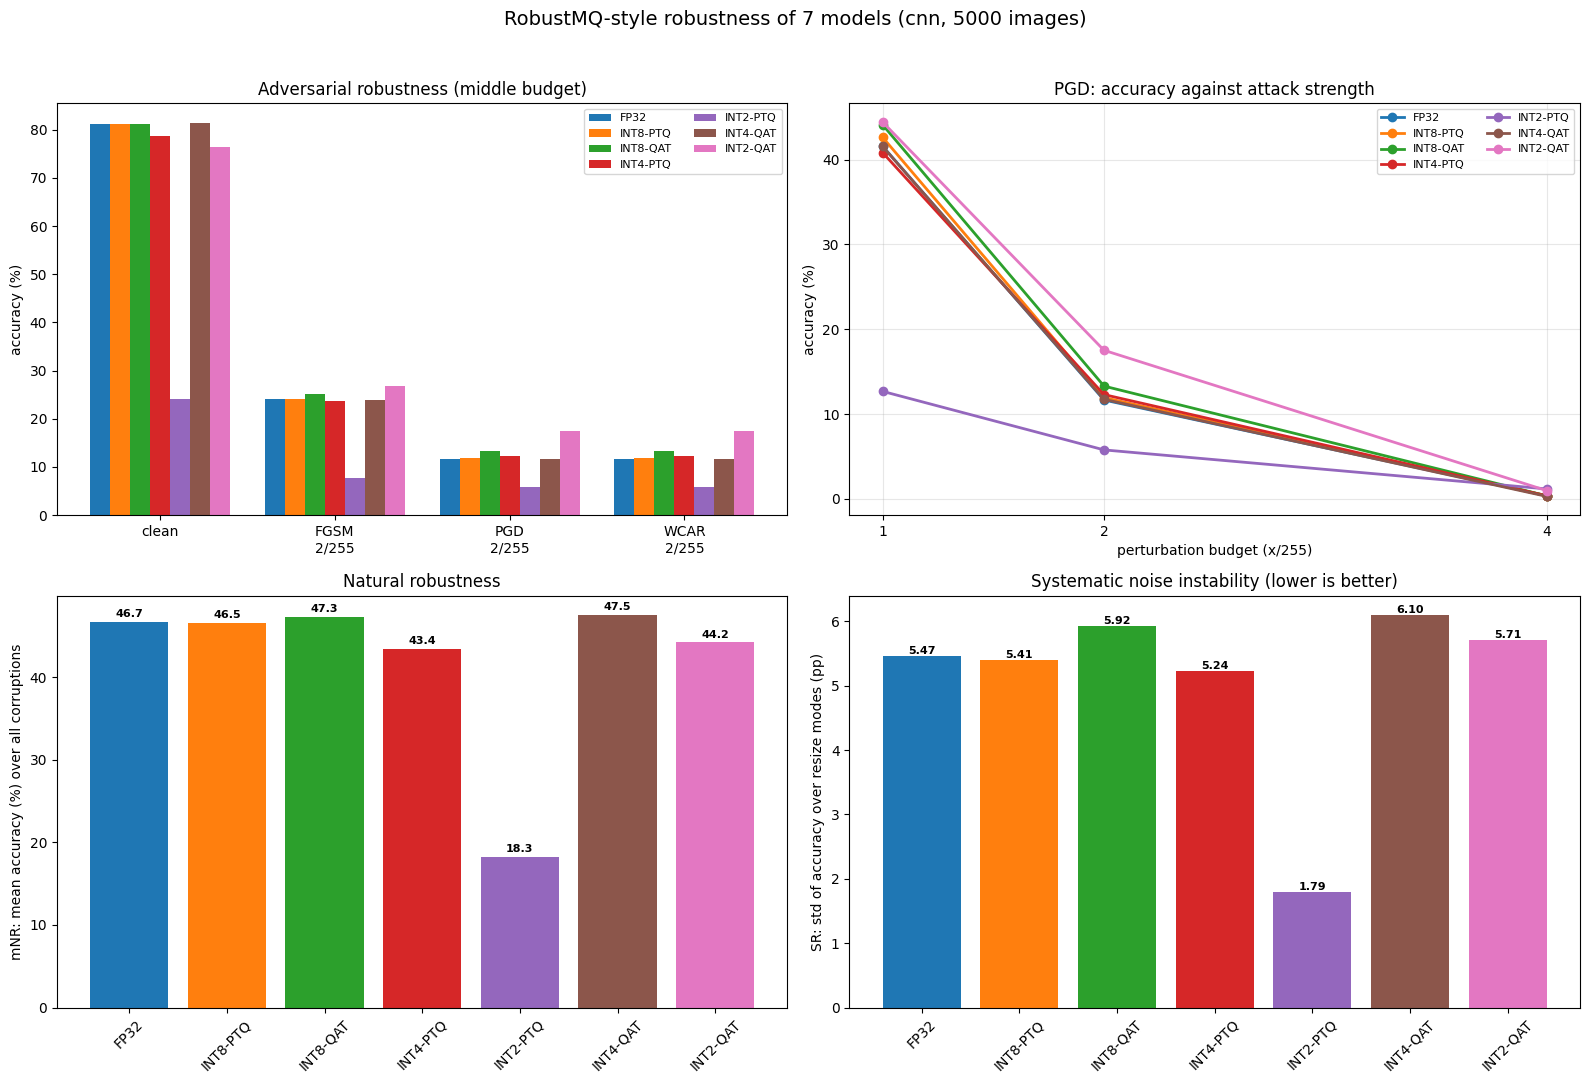

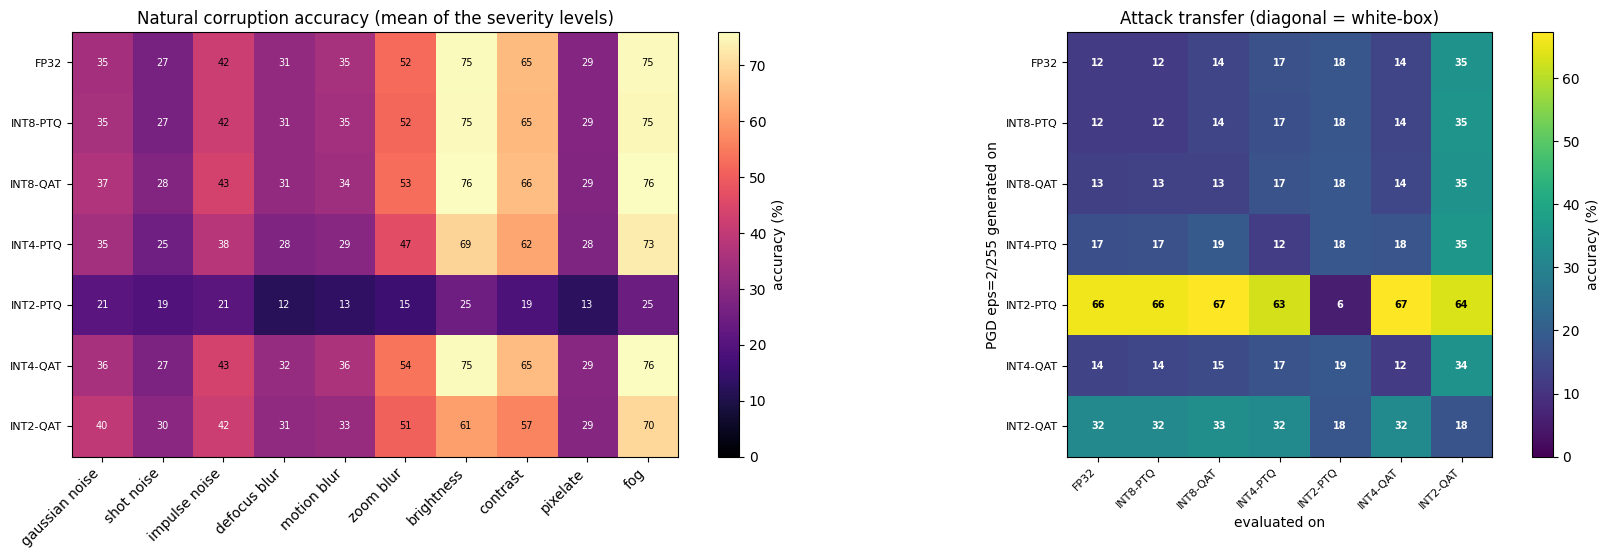

In [8]:
# ===================== Plots =====================
palette = list(plt.cm.tab10.colors)
COLORS = {name: palette[i % 10] for i, name in enumerate(MODEL_NAMES)}
WIDTH = 0.8 / len(MODEL_NAMES)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# (1) clean versus adversarial at the middle budget
ax = axes[0, 0]
bar_labels = ["clean", "FGSM\n2/255", "PGD\n2/255", "WCAR\n2/255"]
positions = np.arange(len(bar_labels))
for i, model_name in enumerate(MODEL_NAMES):
    values = [accuracy_of(model_name, "clean"),
              accuracy_of(model_name, "FGSM eps=2/255"),
              accuracy_of(model_name, "PGD eps=2/255"),
              wcar(model_name, "2/255")]
    ax.bar(positions + (i - (len(MODEL_NAMES) - 1) / 2) * WIDTH, values, WIDTH,
           label=model_name, color=COLORS[model_name])
ax.set_xticks(positions)
ax.set_xticklabels(bar_labels)
ax.set_ylabel("accuracy (%)")
ax.set_title("Adversarial robustness (middle budget)")
ax.legend(fontsize=8, ncol=2)

# (2) accuracy against perturbation budget
ax = axes[0, 1]
budgets = [1, 2, 4]
for model_name in MODEL_NAMES:
    values = [accuracy_of(model_name, f"PGD eps={label}") for label, _ in EPS_LIST]
    ax.plot(budgets, values, marker="o", linewidth=2, label=model_name, color=COLORS[model_name])
ax.set_xlabel("perturbation budget (x/255)")
ax.set_ylabel("accuracy (%)")
ax.set_title("PGD: accuracy against attack strength")
ax.set_xticks(budgets)
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2)

# (3) mean natural robustness
ax = axes[1, 0]
values = [mean_natural_robustness(model_name) for model_name in MODEL_NAMES]
bars = ax.bar(MODEL_NAMES, values, color=[COLORS[m] for m in MODEL_NAMES])
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.6, f"{value:.1f}",
            ha="center", fontsize=8, fontweight="bold")
ax.set_ylabel("mNR: mean accuracy (%) over all corruptions")
ax.set_title("Natural robustness")
ax.tick_params(axis="x", rotation=45)

# (4) systematic instability
ax = axes[1, 1]
values = [systematic_robustness(model_name) for model_name in MODEL_NAMES]
bars = ax.bar(MODEL_NAMES, values, color=[COLORS[m] for m in MODEL_NAMES])
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.03, f"{value:.2f}",
            ha="center", fontsize=8, fontweight="bold")
ax.set_ylabel("SR: std of accuracy over resize modes (pp)")
ax.set_title("Systematic noise instability (lower is better)")
ax.tick_params(axis="x", rotation=45)

fig.suptitle(f"RobustMQ-style robustness of {len(MODEL_NAMES)} models ({ARCH}, {ROBUST_N} images)", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# (5) corruption heatmap and (6) transfer heatmap
corruption_matrix = np.array([[float(np.mean([accuracy_of(m, f"{c} L{l}") for l in SEVERITY_LEVELS]))
                        for c in CORRUPTIONS] for m in MODEL_NAMES])
transfer_matrix = np.array([[transfer_pgd[a][v].float().mean().item() * 100 for v in MODEL_NAMES]
                            for a in MODEL_NAMES])

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
ax = axes[0]
image = ax.imshow(corruption_matrix, cmap="magma", vmin=0, vmax=max(corruption_matrix.max(), 1))
ax.set_xticks(range(len(CORRUPTIONS)))
ax.set_xticklabels(list(CORRUPTIONS), rotation=45, ha="right")
ax.set_yticks(range(len(MODEL_NAMES)))
ax.set_yticklabels(MODEL_NAMES, fontsize=8)
for i in range(len(MODEL_NAMES)):
    for j in range(len(CORRUPTIONS)):
        ax.text(j, i, f"{corruption_matrix[i, j]:.0f}", ha="center", va="center", fontsize=7,
                color="white" if corruption_matrix[i, j] < corruption_matrix.max() * 0.55 else "black")
ax.set_title("Natural corruption accuracy (mean of the severity levels)")
fig.colorbar(image, ax=ax, label="accuracy (%)")

ax = axes[1]
image = ax.imshow(transfer_matrix, cmap="viridis", vmin=0, vmax=max(transfer_matrix.max(), 1))
ax.set_xticks(range(len(MODEL_NAMES)))
ax.set_xticklabels(MODEL_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(MODEL_NAMES)))
ax.set_yticklabels(MODEL_NAMES, fontsize=8)
for i in range(len(MODEL_NAMES)):
    for j in range(len(MODEL_NAMES)):
        ax.text(j, i, f"{transfer_matrix[i, j]:.0f}", ha="center", va="center", fontsize=7,
                fontweight="bold",
                color="white" if transfer_matrix[i, j] < transfer_matrix.max() * 0.55 else "black")
ax.set_xlabel("evaluated on")
ax.set_ylabel(f"PGD eps={TRANSFER_BUDGET} generated on")
ax.set_title("Attack transfer (diagonal = white-box)")
fig.colorbar(image, ax=ax, label="accuracy (%)")
fig.tight_layout()
plt.show()


## How to read these results

Start with the summary table, then the printed rankings at the bottom of the previous cell -- they do the comparison for you.

**The four questions**

1. **Does QAT reproduce the paper's adversarial claim?** The paper found quantized models *more* adversarially robust than FP32, and lower bits even more so. Compare `INT8-QAT` against `FP32` on `WCAR 2/255`; the cell prints that difference and labels it reproduced or not. Then read the per-method bit-width rankings: within `QAT`, is `INT2 > INT4 > INT8`?
2. **Does PTQ behave differently from QAT?** That contrast is the whole point of running both. Expect PTQ to show little or no adversarial gain (v1 measured exactly that) while QAT shows more.
3. **Does natural robustness still fall with bit-width?** Compare `mNR` and `NCI`. The paper's claim is that quantized models (and especially low-bit ones) lose more under corruptions; v1 confirmed this at 4-bit for PTQ.
4. **Do attacks transfer across precisions?** In the transfer heatmap, the **diagonal is the white-box attack** and should be the lowest in each row. A row whose off-diagonal values are much higher than its diagonal means that model's adversarial examples are precision-specific -- the "ensemble of quantized models" defence idea.

**Interpreting the numbers honestly**

- The standard error printed above the rankings tells you the resolution. At `ROBUST_N = 5000` it is about +/-0.6 pp, so treat differences under ~1.2 pp as noise; at 1,000 images the floor is ~2.5 pp.
- `AAI` and `NCI` are the right metrics when clean accuracies differ (they are relative drops). Raw accuracy comparisons across models with different clean accuracy are misleading.
- Compare like with like: a low-bit QAT model that lost 3 pp of clean accuracy is not "more robust" just because its corrupted accuracy is closer to its own clean accuracy. Read `WCAR` and `mNR` together with `ACC`.

**Caveats to state before anyone else does**

- **Not a reproduction of RobustMQ.** They used ImageNet, 4 architectures, 4 bit-widths and LSQ/DoReFa/PACT QAT. We use CIFAR-10, 1 (or 2) architectures, 8/4/2 bits, and two quantization schemes.
- **`INT8-QAT` quantizes activations too; the low-bit QAT models quantize weights only.** That is a real difference between the methods, not a bug: PyTorch's eager QAT supports 8-bit weights *and* activations, while 4/2-bit activation quantization has no kernel here, so the low-bit QAT models use per-channel weight rounding with straight-through gradients.
- **The int8 attacks are surrogate attacks.** Int8 kernels are not differentiable, so those attacks are generated on a float twin carrying the dequantized int8 weights; the twin's agreement with the real model is printed. INT4/INT2/FP32 are attacked exactly.
- **`resnet18` is the ImageNet stem adapted to CIFAR** (3x3 conv, no maxpool) on top of torchvision's *quantizable* ResNet-18, because eager quantization needs `FloatFunctional` for the skip connections. Accuracy will be lower than a purpose-built CIFAR ResNet.
- **Our corruption set is 10 of the paper's 15**, implemented in torch rather than with the official ImageNet-C code, and `fog` is an approximation. Treat the *ordering* as meaningful and the exact values as indicative.
- **Systematic noise here is resize modes only.** RobustMQ also varied image decoders (Pillow/OpenCV/FFmpeg), which cannot be reproduced inside a tensor pipeline.

**Next steps that would strengthen it further**

- Multiple seeds: rerun the file with 3 different `SEED` values and report mean +/- std. Quantized-vs-float differences of 1-2 pp only become claims when they survive reseeding.
- Add `PGD-ℓ2` and a 20-step PGD (or an AutoAttack-style ensemble) to match the paper's third attack.
- Add corruption *sequences* (ImageNet-P style) and report flip probability, which measures stability rather than drop.
- For a real bit-width study, replace the eager 8-bit path with a framework that supports 2/4/6/8-bit activations (the paper's LSQ code), so QAT is applied identically at every width.
